# Experiment 13: Sequential Dataset Preparation and RNN Prediction

A state electricity board must forecast next-hour demand. We simulate a year of hourly consumption with daily and weekly cycles, clean/scale it, form 24-hour windows and train a SimpleRNN using a chronological split.

**Tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib, Scikit-learn.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Load the simulated series with Pandas, interpolate missing values and scale it.  2. Create 24-hour look-back windows.  3. Split chronologically.  4. Train a SimpleRNN.  5. Plot actual/predicted demand and report MAE and RMSE.

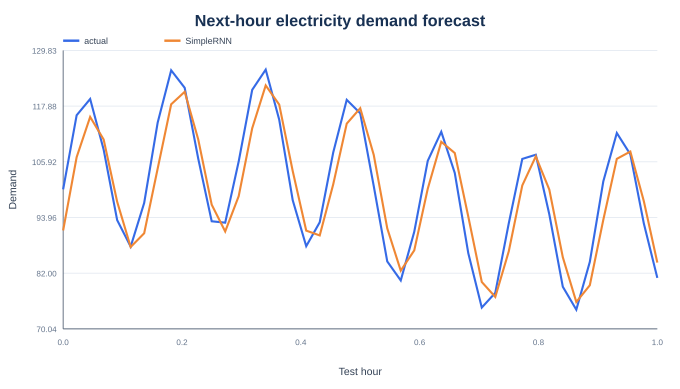

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(13)
rng=np.random.default_rng(13)
hours=np.arange(365*24)
demand=(100 + 18*np.sin(2*np.pi*hours/24) + 9*np.sin(2*np.pi*hours/(24*7))
        + .015*hours + rng.normal(0,3,len(hours)))
series=pd.Series(demand,index=pd.date_range("2025-01-01",periods=len(hours),freq="h"))
series.iloc[rng.choice(len(series),20,replace=False)]=np.nan
series=series.interpolate()
scaler=MinMaxScaler(); scaled=scaler.fit_transform(series.to_numpy()[:,None]).ravel()
lookback=24
X=np.array([scaled[i-lookback:i] for i in range(lookback,len(scaled))],dtype="float32")[...,None]
y=scaled[lookback:].astype("float32")
split=int(.8*len(X)); Xtr,Xte=X[:split],X[split:]; ytr,yte=y[:split],y[split:]
model=tf.keras.Sequential([tf.keras.layers.Input((lookback,1)),
    tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(1)])
model.compile(optimizer="adam",loss="mse")
model.fit(Xtr,ytr,validation_split=.1,epochs=8,batch_size=64,verbose=0)
pred_scaled=model.predict(Xte,verbose=0).ravel()
actual=scaler.inverse_transform(yte[:,None]).ravel()
pred=scaler.inverse_transform(pred_scaled[:,None]).ravel()
print(f"Test MAE={mean_absolute_error(actual,pred):.2f}; RMSE={mean_squared_error(actual,pred)**.5:.2f}")
plt.figure(figsize=(11,4))
plt.plot(actual[:300],label="actual");plt.plot(pred[:300],label="predicted")
plt.xlabel("Test hour");plt.ylabel("Demand (MW)");plt.title("Next-hour electricity demand forecast")
plt.legend();plt.tight_layout();plt.show()